# APM_50441_EP - Machine Learning 2 - Lab 3: Trees, ensembles, SVM and tabular deep learning

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/APM-50441-EP/APM_50441_EP-2026-2027/blob/main/PC3/APM_50441_EP_Lab_3_with_solution.ipynb) or run it on your own computer (see *Working environment* below).

This lab illustrates the third lecture (*Trees, Ensemble Methods, SVM and Tabular Deep Learning*). Its goals are:
- to grow and prune a classification tree (CART),
- to understand why averaging trees works (bagging, random forests, extra trees) and to use the out-of-bag estimate,
- to implement AdaBoost and to tune a gradient boosting (learning rate, number of trees, early stopping),
- to use a support vector machine with a kernel,
- to compare all these methods honestly, with the cost-based gain of Lab 1.

The optional *To go further* part, after the core, can be skipped at first.

We use `Python` with `scikit-learn`, `polars` and `seaborn`.

**Working environment.** Colab is the simplest option: open the notebook of this lab from the course repository (*Open in Colab* link) and run it. To work on your own computer, download the lab folder (the notebook and its files) or clone the course repository, and open the notebook in an IDE that runs Jupyter notebooks (VS Code with the Python and Jupyter extensions, JupyterLab, Spyder, PyCharm). Create a Python environment once with [`uv`](https://docs.astral.sh/uv/): `uv venv`, activate it (`source .venv/bin/activate`, or `.venv\Scripts\activate` on Windows) and `uv pip install jupyter`, or build the whole course environment with `uv sync` in `PC/env`; then select this environment as the kernel of the notebook. The installation cell below installs the packages of the lab into the Python running the notebook (Colab or your environment), and the data are read from the local files when they are present (otherwise they are downloaded).

**Use of AI.** AI assistants are allowed, but you must be able to explain every line you use, and you should answer the *predict before you run* questions before running the code: the suggested code may not be correct!

All the libraries of the core part are installed at once. On Colab, restart the session once after this installation; locally, restart the kernel if the installation upgraded a package that was already loaded.

In [2]:
# Installs into the Python running this notebook: Colab, or locally an activated virtual environment
import sys
!uv pip install --python "{sys.executable}" "scikit-learn==1.9.1" "polars==1.44.2" "seaborn==0.13.2" "fairlearn==0.14.0"

Using Python 3.12.14 environment at: ~\.venvs\apm50441
Checked 4 packages in 23ms


We use again the German credit data of Lab 1 and its cost model (`apm_credit.py`): the scorers `cost_scorer` and `cost_scorer_from_proba` return the real-world *gain* (the opposite of the cost) of the predictions, and of the Bayes decision computed from the probabilities.

In [3]:
import os
import urllib.request

# each file is downloaded only if there is no local copy
CSV_URL = "https://raw.githubusercontent.com/IBM/monitor-wml-model-with-watson-openscale/master/data/german_credit_data_biased_training.csv"
APM_CREDIT_URL = "https://raw.githubusercontent.com/APM-50441-EP/APM_50441_EP-2026-2027/main/common/apm_credit.py"  # course repository
for url in [CSV_URL, APM_CREDIT_URL]:
  filename = url.split('/')[-1]
  if not os.path.exists(filename):
    urllib.request.urlretrieve(url, filename)

The data, the split, the preprocessing and the cost model are given (Lab 1).

In [4]:
import time
import numpy as np
import polars as pl
import polars.selectors as cs
import seaborn.objects as so
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, RepeatedStratifiedKFold
from threadpoolctl import threadpool_limits
threadpool_limits(limits=2, user_api='openmp')  # on such small datasets, many threads are slower than a few

import apm_credit
from apm_credit import cost_scorer, cost_scorer_from_proba, cost_metric

german_credit = pl.read_csv("german_credit_data_biased_training.csv")
X = german_credit.drop('Risk')
y = german_credit['Risk']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
LoanAmount_train, LoanAmount_test = X_train['LoanAmount'], X_test['LoanAmount']
apm_credit.set_proportions(y_train, {'Risk': .02, 'No Risk': .98})

categorical_features = X.select(cs.string()).columns
numerical_features = X.select(cs.numeric()).columns
preprocessor = ColumnTransformer(transformers=[
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features),
    ('num', StandardScaler(), numerical_features)]).set_output(transform='polars')

def make_pipeline(classifier):
  return Pipeline(steps=[('preprocessor', clone(preprocessor)), ('classifier', classifier)])

# the preprocessed matrices, for the methods implemented by hand
Xp_train = clone(preprocessor).fit(X_train).transform(X_train)
Xp_test = clone(preprocessor).fit(X_train).transform(X_test)
feature_names = Xp_train.columns
Xp_train, Xp_test = Xp_train.to_numpy(), Xp_test.to_numpy()
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
Xp_train.shape

(4000, 60)

## 1. Classification trees

CART grows a tree greedily: each split is chosen to decrease an impurity (Gini index by default) as much as possible, until the leaves are pure or too small. A fully grown tree overfits; it is then *pruned* along the sequence of subtrees minimizing the penalized criterion $\text{error} + \alpha \times \text{number of leaves}$ (cost-complexity pruning), $\alpha$ being chosen by cross validation.

**Question** *Predict before you run:* what are the training and test accuracies of a fully grown tree? Fit it, and report its depth and its number of leaves.

**Answer**

In [5]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
full_tree = make_pipeline(DecisionTreeClassifier(random_state=0)).fit(X_train, y_train)
tree_ = full_tree.named_steps['classifier']
{'depth': tree_.get_depth(), 'leaves': tree_.get_n_leaves(),
 'training accuracy': full_tree.score(X_train, y_train), 'test accuracy': full_tree.score(X_test, y_test)}

{'depth': 29,
 'leaves': np.int64(703),
 'training accuracy': 1.0,
 'test accuracy': 0.701}

**Conclusion** The fully grown tree has a depth of $29$ and $703$ leaves (fewer than $6$ loans per leaf on average): it classifies the training set perfectly but reaches only $0.70$ on the test set, barely more than always predicting `No Risk` ($0.67$). A fully grown tree has a very small bias and a very large variance: it memorizes the training set, noise included.

---

**Question** Compute the cost-complexity pruning path of the full tree (`cost_complexity_pruning_path`). For about $30$ values of $\alpha$ along the path, compute the training accuracy and the $5$-fold CV accuracy, and plot them against the number of leaves. Select $\alpha$ by cross validation, and plot the top of the pruned tree.

**Answer**

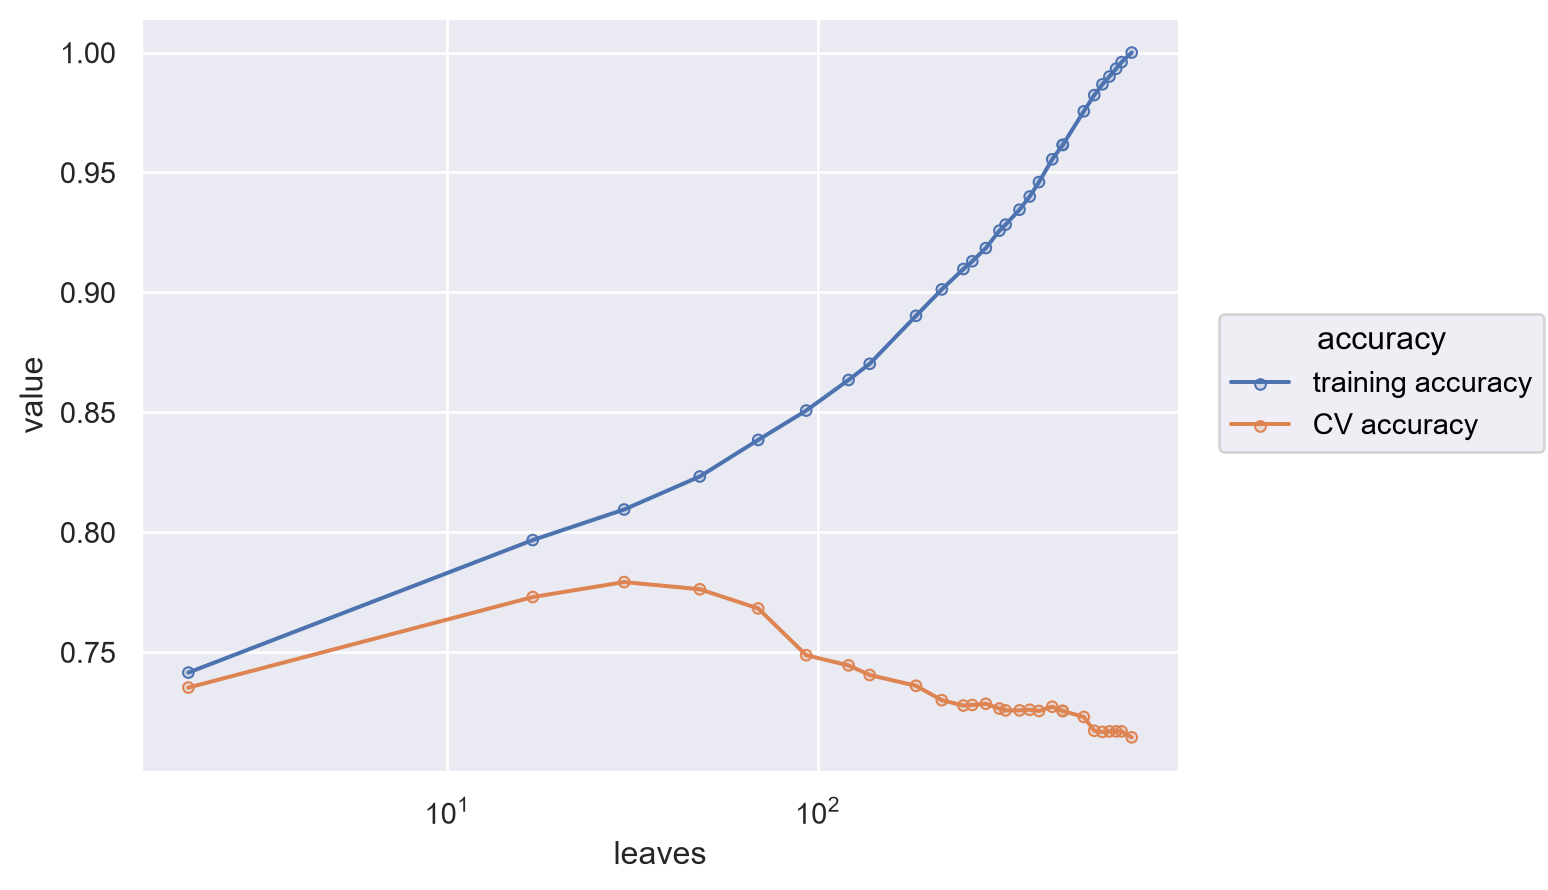

In [6]:
path = DecisionTreeClassifier(random_state=0).cost_complexity_pruning_path(Xp_train, y_train)
alphas = np.unique(np.quantile(path.ccp_alphas[:-1], np.linspace(0, 1, 30)))
pruning = []
for alpha in alphas:
  tree = DecisionTreeClassifier(random_state=0, ccp_alpha=alpha).fit(Xp_train, y_train)
  pruning.append({'alpha': alpha, 'leaves': tree.get_n_leaves(), 'training accuracy': tree.score(Xp_train, y_train),
                  'CV accuracy': cross_val_score(DecisionTreeClassifier(random_state=0, ccp_alpha=alpha), Xp_train, y_train, cv=cv5).mean()})
pruning = pl.DataFrame(pruning)
best_alpha = pruning.filter(pl.col('CV accuracy') == pl.col('CV accuracy').max())['alpha'][0]
(so.Plot(pruning.unpivot(index=['alpha', 'leaves'], variable_name='accuracy'), x='leaves', y='value', color='accuracy')
 .add(so.Line()).add(so.Dots()).scale(x='log'))

{'alpha': 0.0010633395246170848, 'leaves': np.int64(30), 'test accuracy': 0.794}


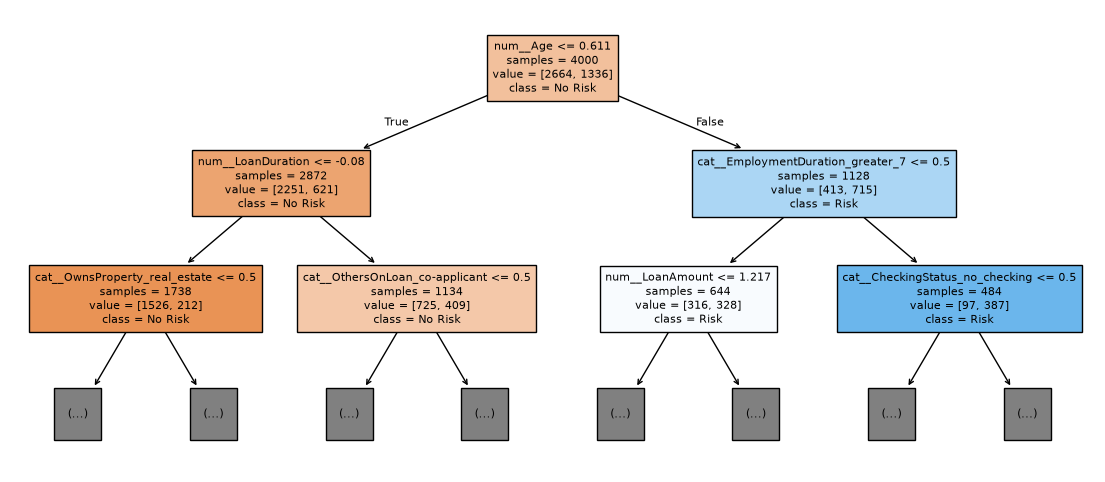

In [7]:
pruned_tree = DecisionTreeClassifier(random_state=0, ccp_alpha=best_alpha).fit(Xp_train, y_train)
print({'alpha': best_alpha, 'leaves': pruned_tree.get_n_leaves(), 'test accuracy': pruned_tree.score(Xp_test, y_test)})
fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(pruned_tree, max_depth=2, feature_names=list(feature_names), class_names=list(pruned_tree.classes_), filled=True,
          impurity=False, fontsize=8, ax=ax);

**Conclusion** Along the pruning path, the training accuracy decreases steadily when leaves are removed, while the CV accuracy increases up to about $30$ leaves ($0.78$) and decreases for smaller trees: the classical bias-variance trade-off, with the number of leaves as complexity. The tree selected by cross validation ($\alpha \approx 0.001$, $30$ leaves) reaches $0.79$ on the test set, $9$ points more than the full tree, and is readable: its first splits use the age, the loan duration and the employment duration, then the property, a co-applicant, the amount and the checking account.

---

## 2. Averaging trees: bagging, random forests and extra trees

A deep tree has a small bias but a large variance. *Bagging* averages $B$ trees grown on bootstrap samples: the variance of the average of $B$ identically distributed predictors of variance $\sigma^2$ and pairwise correlation $\rho$ is $\rho\sigma^2 + (1-\rho)\sigma^2/B$. *Random forests* decrease $\rho$ by choosing each split among a random subset of $m$ features (`max_features`); *extra trees* also draw the thresholds at random.

**Question** *Predict before you run:* how does the variance of the predicted probabilities change from a single deep tree to the bagging of $100$ trees? Measure it: train both on $10$ random subsamples ($80\%$) of the training set, and compute, for each test loan, the variance of its predicted probability of `Risk` across the subsamples (averaged over the test loans). Compare also their test accuracies.

**Answer**

In [8]:
from sklearn.ensemble import BaggingClassifier
rng = np.random.default_rng(0)
probas = {'single tree': [], 'bagging (100 trees)': []}
accuracies = {'single tree': [], 'bagging (100 trees)': []}
for r in range(10):
  idx = rng.choice(len(Xp_train), size=int(0.8 * len(Xp_train)), replace=False)
  for name, model in {'single tree': DecisionTreeClassifier(random_state=r),
                      'bagging (100 trees)': BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, random_state=r, n_jobs=2)}.items():
    model.fit(Xp_train[idx], y_train.to_numpy()[idx])
    probas[name].append(model.predict_proba(Xp_test)[:, 1])
    accuracies[name].append(model.score(Xp_test, y_test))
pl.DataFrame([{'model': name, 'mean variance of the probability': np.var(np.array(probas[name]), axis=0).mean(),
               'mean test accuracy': np.mean(accuracies[name])} for name in probas])

model,mean variance of the probability,mean test accuracy
str,f64,f64
"""single tree""",0.12139,0.7261
"""bagging (100 trees)""",0.003125,0.8022


**Conclusion** Over $10$ subsamples of the training set, the probability predicted by a deep tree for a given loan varies a lot (mean variance $0.12$: the predictions jump between $0$ and $1$), while the bagging of $100$ trees has a mean variance of $0.003$, $40$ times smaller. The test accuracy improves accordingly, from $0.73$ to $0.80$: averaging trees keeps their small bias and removes most of their variance (the remaining part, $\rho\sigma^2$, comes from the correlation between the trees).

---

**Question** Random forests: for `max_features` in $\{1, 3, 8, 20, \text{all } p\}$ ($p$ = number of one-hot encoded features; all means bagging), compute the out-of-bag (OOB) accuracy of a forest of $300$ trees (`oob_score=True`). Which value is best? Compare with the recommendation $m \approx \sqrt{p}$.

**Answer**

In [9]:
from sklearn.ensemble import RandomForestClassifier
p = Xp_train.shape[1]
max_features = pl.DataFrame([{'max_features': m, 'OOB accuracy': RandomForestClassifier(n_estimators=300, max_features=m, oob_score=True,
                                                                                         random_state=0, n_jobs=2).fit(Xp_train, y_train).oob_score_}
                             for m in [1, 3, 8, 20, p]])
print('p =', p, ' sqrt(p) =', round(np.sqrt(p), 1))
max_features

p = 60  sqrt(p) = 7.7


max_features,OOB accuracy
i64,f64
1,0.7975
3,0.796
8,0.8025
20,0.80375
60,0.79725


**Conclusion** The OOB accuracies are all between $0.796$ and $0.804$: $m = 8$ and $m = 20$ are the best, close to the recommendation $\sqrt{p} \approx 7.7$, and bagging ($m = 60$) is slightly worse. The differences are small here (of the order of the noise of the OOB estimate on $4000$ loans): the decorrelation brought by the random choice of the features helps, but the forest is not very sensitive to $m$ in a wide range, which is one reason for its popularity as a default method.

---

**Question** Grow a random forest ($m = 8$) with `warm_start=True` from $10$ to $500$ trees, and plot, as a function of the number of trees, its OOB accuracy, its $5$-fold CV accuracy (for a few numbers of trees) and its test accuracy. Is the OOB estimate reliable? What does it cost?

**Answer**

~\.venvs\apm50441\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


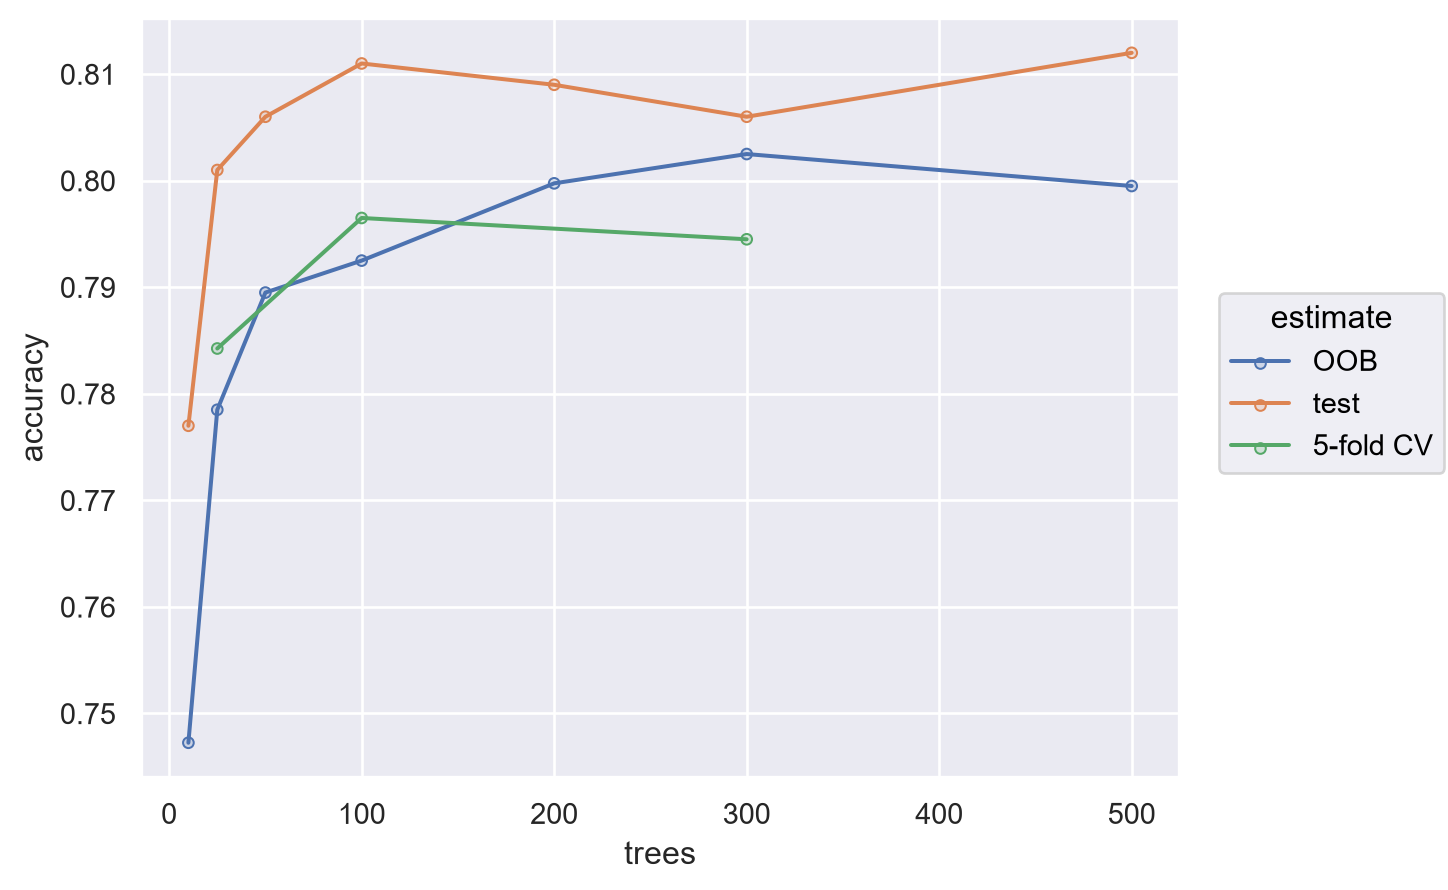

In [10]:
forest = RandomForestClassifier(max_features=8, oob_score=True, warm_start=True, random_state=0, n_jobs=2)
growth = []
for n_trees in [10, 25, 50, 100, 200, 300, 500]:
  forest.set_params(n_estimators=n_trees).fit(Xp_train, y_train)
  row = {'trees': n_trees, 'OOB': forest.oob_score_, 'test': forest.score(Xp_test, y_test)}
  if n_trees in [25, 100, 300]:
    row['5-fold CV'] = cross_val_score(RandomForestClassifier(n_estimators=n_trees, max_features=8, random_state=0, n_jobs=2),
                                       Xp_train, y_train, cv=cv5).mean()
  growth.append(row)
growth = pl.DataFrame(growth)
so.Plot(growth.unpivot(index='trees', variable_name='estimate', value_name='accuracy').drop_nulls(), x='trees', y='accuracy',
        color='estimate').add(so.Line()).add(so.Dots())

**Conclusion** The OOB accuracy increases with the number of trees and stabilizes around $0.80$ after $200$ trees (with few trees, some loans are in all the bootstrap samples and have no OOB prediction, hence the warning). It is close to the $5$-fold CV estimate ($0.79$–$0.80$), which costs $5$ times more fits, while the OOB estimate is free: each tree is evaluated on the loans it has not seen. Both are a bit pessimistic compared with the test accuracy ($0.81$), within the noise of a single test set. More trees stabilize the vote. Adding a tree can still flip a prediction and decrease accuracy on a finite test set.

---

**Question** Compare the impurity-based importances of the forest (`feature_importances_`) with the permutation importances on the test set (`permutation_importance`, $5$ repeats). Which features matter? Why can the two rankings differ?

**Answer**

In [11]:
from sklearn.inspection import permutation_importance
permutation = permutation_importance(forest, Xp_test, y_test, n_repeats=5, random_state=0)
importances = pl.DataFrame({'feature': list(feature_names), 'impurity': forest.feature_importances_,
                            'permutation': permutation.importances_mean})
importances.sort('impurity', descending=True).head(10).with_columns(
    pl.col('permutation').rank(descending=True).alias('rank (permutation)'))

feature,impurity,permutation,rank (permutation)
str,f64,f64,f64
"""num__LoanAmount""",0.105812,0.0016,6.0
"""num__Age""",0.105005,0.0004,9.0
"""num__LoanDuration""",0.094414,0.0062,2.0
"""num__CurrentResidenceDuration""",0.044446,0.0048,4.0
"""cat__CheckingStatus_no_checkin…",0.036637,0.0006,8.0
"""num__ExistingCreditsCount""",0.035447,-0.0002,10.0
"""num__InstallmentPercent""",0.033933,0.0028,5.0
"""cat__EmploymentDuration_greate…",0.032332,0.0072,1.0
"""cat__OwnsProperty_unknown""",0.021623,0.0008,7.0


**Conclusion** The impurity-based importances favor the numerical features (amount, age, duration...), which offer many possible split points: they are computed on the training set and are biased towards variables with many values, even if the splits on them partly fit noise (the age and the amount have a very small permutation importance). The permutation importances on the test set measure the loss of accuracy when a feature is shuffled: the employment duration, the loan duration, the absence of other people on the loan and the residence duration matter most, but all the values are small (less than $0.01$): with correlated or one-hot encoded features, the information of a shuffled column is partly available in the others.

---

## 3. Boosting

Boosting builds a sequence of *weak* learners, each one focusing on the errors of the previous ones. AdaBoost (Lecture 3 and PC3) uses labels $y_i \in \{-1, 1\}$, weights $w_i$ starting from $1/n$, and at each step $t$:
- fit a weak learner $h_t$ (here a *stump*, a tree of depth $1$) with the weights $w$, and compute its weighted error $\varepsilon_t = \sum_i w_i \mathbf{1}_{h_t(x_i) \neq y_i}$,
- set $\alpha_t = \frac{1}{2}\log\frac{1-\varepsilon_t}{\varepsilon_t}$,
- update $w_i \leftarrow w_i \exp(-\alpha_t y_i h_t(x_i))$ and normalize the weights,

and predicts $\text{sign}\left(\sum_t \alpha_t h_t(x)\right)$.

**Question** Complete the function `adaboost` below, run it for $200$ steps, and plot its training and test accuracies as functions of the number of steps. Stop on a perfect learner or a learner with no positive edge. Assign an ensemble score of zero to class $-1$. Compare with the `staged_score` of a scikit-learn `AdaBoostClassifier` with a depth-one decision tree and 200 estimators. Note: `scikit-learn`'s `estimator_weights_` are equal to $2\alpha_t$ (another normalization of the same algorithm); compare them with your $\alpha_t$.

In [12]:
def adaboost(X, y, T):
  """AdaBoost with stumps; y in {-1, 1}. Returns the list of (alpha_t, h_t)."""
  n = len(y)
  w = np.full(n, 1 / n)
  learners = []
  for t in range(T):
    h = DecisionTreeClassifier(max_depth=1).fit(X, y, sample_weight=w)
    # complete: weighted error, stopping conditions, alpha, update and normalization of the weights
    ...
  return learners

**Answer**

In [13]:
def adaboost(X, y, T):
  """AdaBoost with stumps; y in {-1, 1}. Returns the list of (alpha_t, h_t)."""
  n = len(y)
  w = np.full(n, 1 / n)
  learners = []
  for t in range(T):
    h = DecisionTreeClassifier(max_depth=1).fit(X, y, sample_weight=w)
    pred = h.predict(X)
    eps = np.sum(w * (pred != y))
    if eps == 0:
      learners.append((1 + sum(abs(a) for a, _ in learners), h))
      break
    if eps >= 0.5:
      break
    alpha = 0.5 * np.log((1 - eps) / eps)
    w = w * np.exp(-alpha * y * pred)
    w = w / w.sum()
    learners.append((alpha, h))
  return learners

def staged_accuracy(learners, X, y):
  if not learners:
    return np.empty(0)
  scores = np.cumsum([alpha * h.predict(X) for alpha, h in learners], axis=0)
  return (np.where(scores > 0, 1, -1) == y).mean(axis=1)

y_pm_train = np.where(y_train.to_numpy() == 'Risk', 1, -1)
y_pm_test = np.where(y_test.to_numpy() == 'Risk', 1, -1)
learners = adaboost(Xp_train, y_pm_train, 200)

first alphas (ours): [0.527 0.232 0.235 0.17  0.127]
estimator_weights_ / 2: [0.527 0.232 0.235 0.17  0.127]


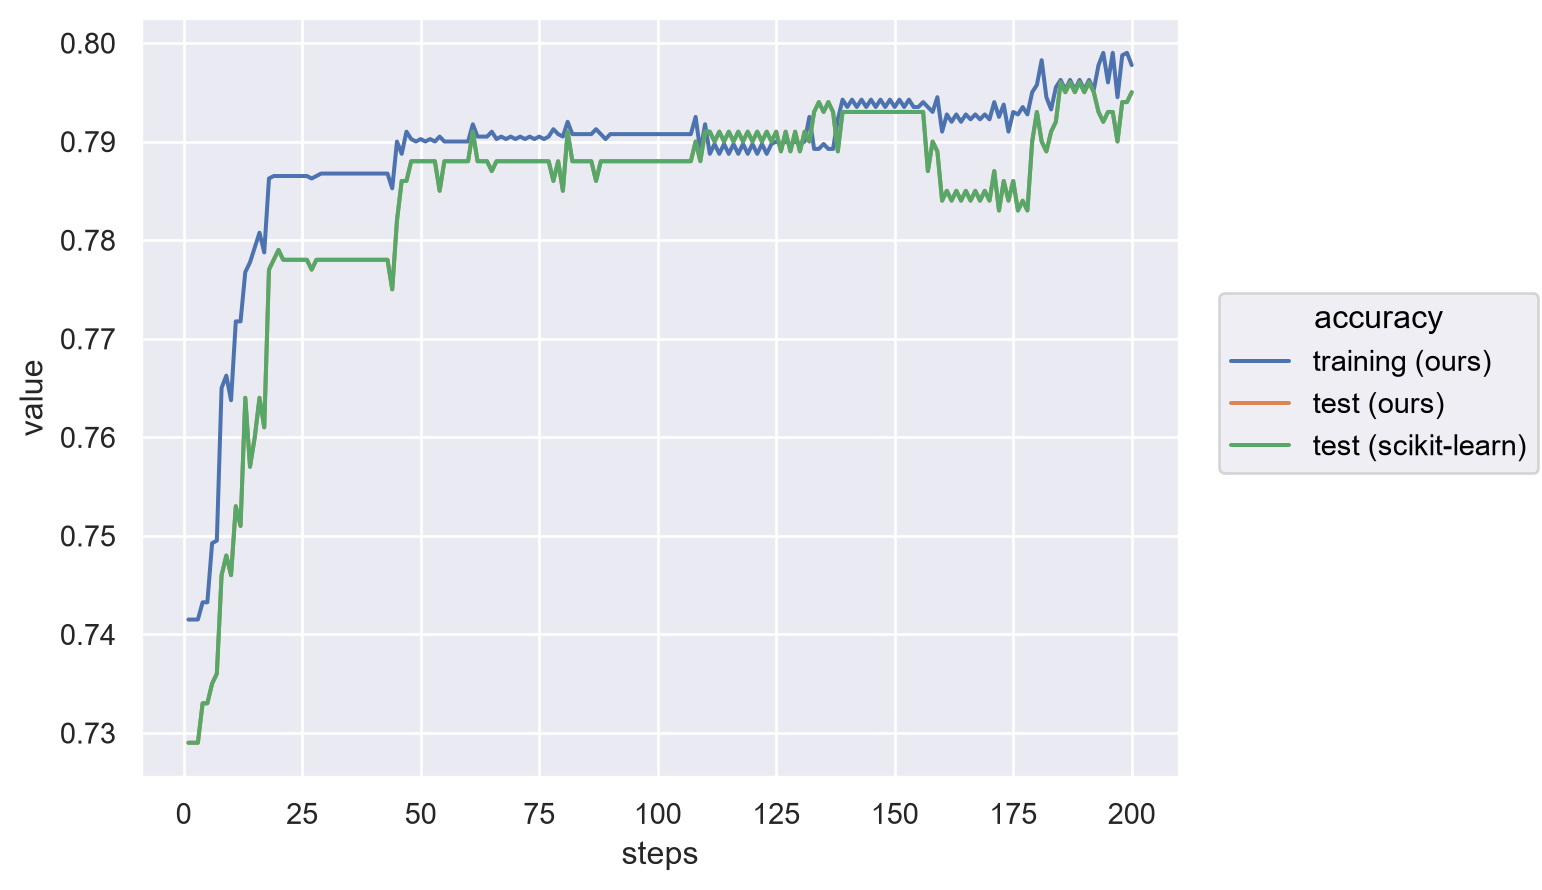

In [14]:
from sklearn.ensemble import AdaBoostClassifier
ada = AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=200, random_state=0).fit(Xp_train, y_pm_train)
stages = min(len(learners), len(ada.estimators_))
curves = pl.DataFrame({'steps': np.arange(1, stages + 1),
                       'training (ours)': staged_accuracy(learners[:stages], Xp_train, y_pm_train),
                       'test (ours)': staged_accuracy(learners[:stages], Xp_test, y_pm_test),
                       'test (scikit-learn)': list(ada.staged_score(Xp_test, y_pm_test))[:stages]})
print('first alphas (ours):', np.round([a for a, _ in learners[:5]], 3))
print('estimator_weights_ / 2:', np.round(ada.estimator_weights_[:5] / 2, 3))
so.Plot(curves.unpivot(index='steps', variable_name='accuracy'), x='steps', y='value', color='accuracy').add(so.Line())

**Conclusion** Our implementation gives exactly the same test accuracies as `AdaBoostClassifier` along the iterations (the two test curves coincide), and our $\alpha_t$ are half of scikit-learn's `estimator_weights_` ($0.527, 0.232, \dots$), the factor $2$ of PC3. The first stump already reaches $0.73$; the accuracy then increases by steps up to about $0.79$ after $50$ stumps, and only slowly afterwards, the training accuracy staying close to the test accuracy: with stumps, AdaBoost builds an additive model without interactions, with a large bias and little overfitting.

---

*Gradient boosting* generalizes boosting to any differentiable loss: each new tree fits the negative gradient of the loss at the current predictions, and is added with a small *learning rate* (shrinkage). The learning rate and the number of trees must be tuned together; *early stopping* stops adding trees when a validation score does not improve anymore.

**Question** Fit `GradientBoostingClassifier` (trees of depth $3$, $600$ trees) with learning rates $1$, $0.1$ and $0.01$, and plot the validation log loss as a function of the number of trees (use `staged_predict_proba` on a validation split of the training set). Then fit a `HistGradientBoostingClassifier` with early stopping: how many iterations does it keep?

**Answer**

shape: (3, 3)
┌───────────────┬──────────┬──────────┐
│ learning rate ┆ best     ┆ at trees │
│ ---           ┆ ---      ┆ ---      │
│ str           ┆ f64      ┆ i64      │
╞═══════════════╪══════════╪══════════╡
│ 0.1           ┆ 0.422839 ┆ 80       │
│ 1             ┆ 0.491102 ┆ 10       │
│ 0.01          ┆ 0.424763 ┆ 600      │
└───────────────┴──────────┴──────────┘


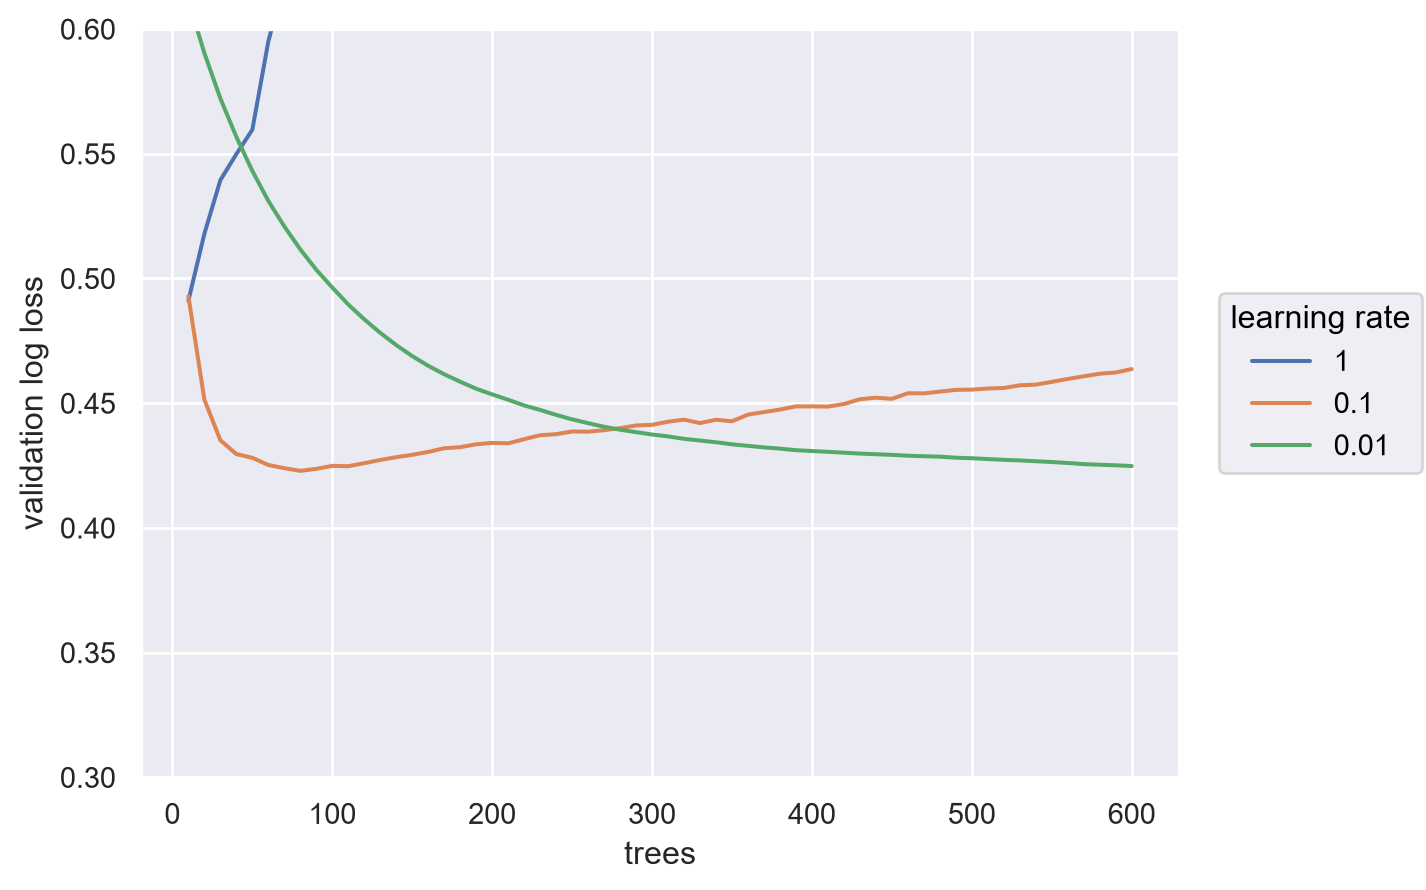

In [15]:
from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.metrics import log_loss
Xp_fit, Xp_valid, y_fit, y_valid = train_test_split(Xp_train, y_train.to_numpy(), test_size=0.25, random_state=0, stratify=y_train)
staged = []
for lr in [1, 0.1, 0.01]:
  gb = GradientBoostingClassifier(learning_rate=lr, n_estimators=600, max_depth=3, random_state=0).fit(Xp_fit, y_fit)
  staged += [{'learning rate': str(lr), 'trees': t + 1, 'validation log loss': log_loss(y_valid, proba)}
             for t, proba in enumerate(gb.staged_predict_proba(Xp_valid)) if (t + 1) % 10 == 0]
staged = pl.DataFrame(staged)
print(staged.group_by('learning rate').agg(pl.col('validation log loss').min().alias('best'),
                                           pl.col('trees').sort_by('validation log loss').first().alias('at trees')))
so.Plot(staged, x='trees', y='validation log loss', color='learning rate').add(so.Line()).limit(y=(0.3, 0.6))

In [16]:
hgb = HistGradientBoostingClassifier(early_stopping=True, max_iter=1000, learning_rate=0.1, random_state=0).fit(Xp_train, y_train)
{'iterations kept': hgb.n_iter_, 'test accuracy': hgb.score(Xp_test, y_test)}

{'iterations kept': 50, 'test accuracy': 0.809}

**Conclusion** With a learning rate of $1$, the validation log loss is minimal after $10$ trees ($0.49$) and then increases quickly: each tree corrects too much and the boosting overfits. With $0.1$, the minimum ($0.423$) is reached after $80$ trees and the loss then increases slowly; with $0.01$, the loss is still decreasing after $600$ trees ($0.425$). Smaller learning rates need proportionally more trees and give a curve that is flatter around its minimum (less sensitive to the number of trees), with a similar best value: the number of trees must be tuned *with* the learning rate, which is what early stopping does. The histogram gradient boosting with early stopping keeps $50$ iterations and reaches a test accuracy of $0.81$.

---

## 4. Support vector machines

An SVM minimizes the hinge loss with a ridge penalty, $\frac{1}{n}\sum_i \max(0, 1 - y_i f(x_i)) + \lambda\|f\|^2$, with $C \propto 1/(n\lambda)$ (PC2). With a kernel $k(x, x') = \exp(-\gamma\|x - x'\|^2)$, $f$ lives in the space of functions $\sum_i \beta_i k(x_i, \cdot)$, and only the *support vectors* (the observations on or inside the margin) have $\beta_i \neq 0$. The features must be standardized.

**Question** Tune an RBF SVM (`SVC`) on the grid $C \in \{0.1, 1, 10, 100\}$, $\gamma \in \{0.001, 0.01, 0.1, 1\}$ with a $3$-fold CV of the accuracy. Plot the CV accuracy on the grid, and the number of support vectors as a function of $C$ (for the best $\gamma$). Comment.

**Answer**

{'classifier__C': 10, 'classifier__gamma': 0.01} 0.8105


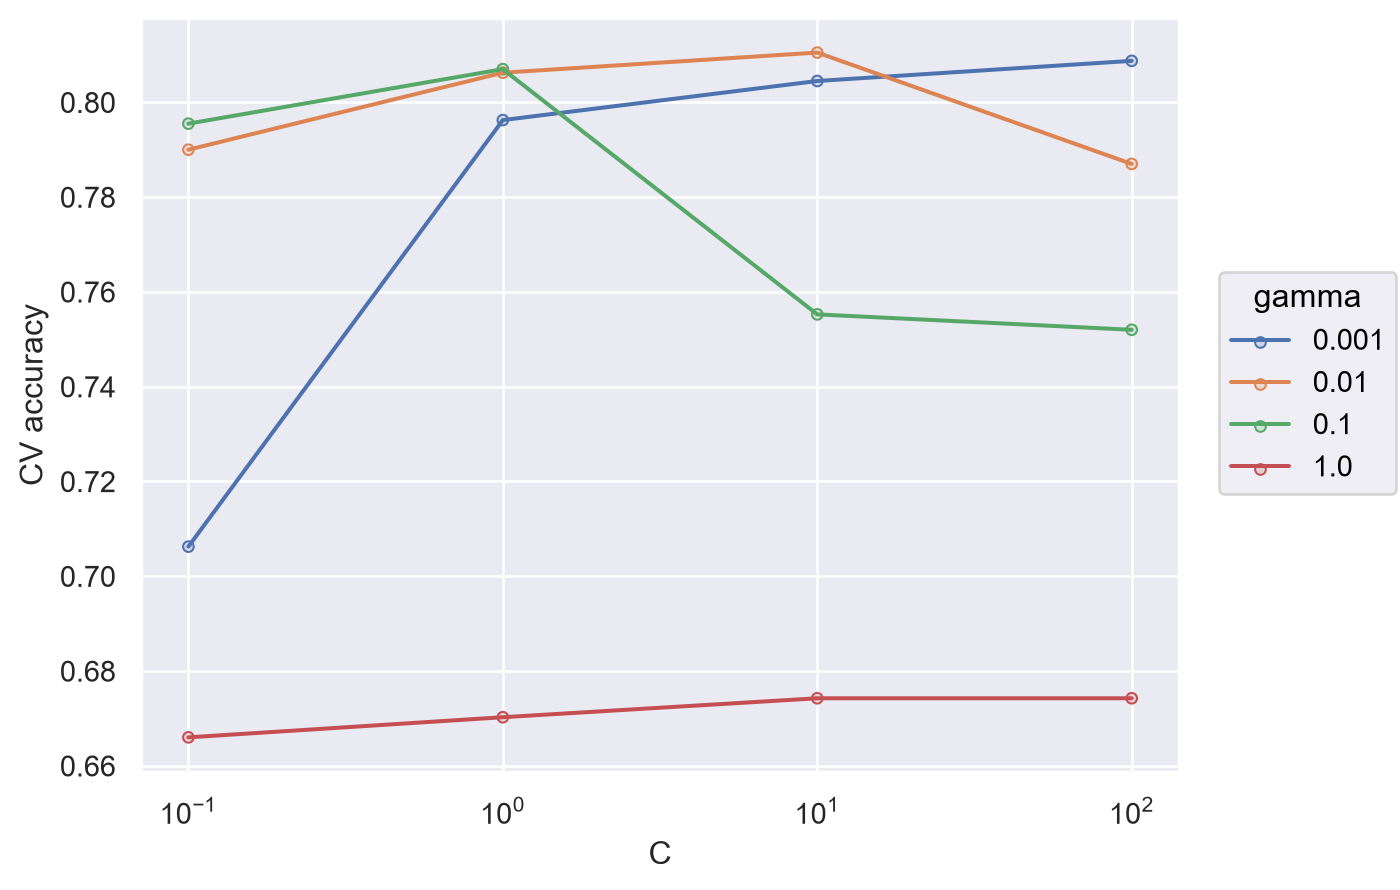

In [17]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
svm_grid = GridSearchCV(make_pipeline(SVC(kernel='rbf')), {'classifier__C': [0.1, 1, 10, 100], 'classifier__gamma': [0.001, 0.01, 0.1, 1]},
                        cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=0), n_jobs=2).fit(X_train, y_train)
svm_results = pl.DataFrame({'C': svm_grid.cv_results_['param_classifier__C'].astype(float),
                            'gamma': svm_grid.cv_results_['param_classifier__gamma'].astype(float),
                            'CV accuracy': svm_grid.cv_results_['mean_test_score']})
print(svm_grid.best_params_, round(svm_grid.best_score_, 4))
so.Plot(svm_results, x='C', y='CV accuracy', color=svm_results['gamma'].cast(pl.String)).add(so.Line()).add(so.Dots()).scale(x='log')

In [18]:
best_gamma = svm_grid.best_params_['classifier__gamma']
pl.DataFrame([{'C': C, 'support vectors': int(make_pipeline(SVC(C=C, gamma=best_gamma)).fit(X_train, y_train)
                                               .named_steps['classifier'].n_support_.sum())} for C in [0.1, 1, 10, 100]])

C,support vectors
f64,i64
0.1,2189
1.0,1932
10.0,1851
100.0,1854


**Conclusion** The best CV accuracy ($0.81$) is obtained for $C = 10$ and $\gamma = 0.01$, with a ridge of good values along the diagonal: a larger $\gamma$ (a more local kernel) needs a smaller $C$ (more regularization) and conversely. With $\gamma = 1$, the kernel is so local that the SVM memorizes the training set (CV accuracy $0.67$, the proportion of the majority class). The number of support vectors is very large ($1850$ to $2190$ of the $4000$ loans) and decreases with $C$: the classes overlap a lot, and all the loans inside the margin or misclassified are support vectors. The prediction cost of an SVM grows with this number.

---

## 5. An honest comparison with the cost-based gain

We finally compare the methods with the criterion that matters for the bank: the real-world gain of the Bayes decision computed from their probabilities (`cost_scorer_from_proba`, Lab 1). All the models are evaluated on the same $5 \times 2$ repeated stratified folds, so that their differences can be paired.

**Question** Evaluate the logistic regression, the pruned tree, the random forest, the extra trees, AdaBoost, the histogram gradient boosting and the SVM with two repeats of five-fold stratified CV. For SVM probabilities use Platt calibration with `CalibratedClassifierCV` and set `ensemble=False`. Tune pruning and SVM parameters within each outer training split. Display the mean and range of outer-fold gains, compare the prespecified SVM and logistic regression with the corrected resampled $t$-test of Lab 1, and evaluate the best one once on the test set.

**Answer**

shape: (7, 4)
┌───────────────────┬───────────┬───────────┬────────────┐
│ model             ┆ mean gain ┆ lower     ┆ upper      │
│ ---               ┆ ---       ┆ ---       ┆ ---        │
│ str               ┆ f64       ┆ f64       ┆ f64        │
╞═══════════════════╪═══════════╪═══════════╪════════════╡
│ AdaBoost          ┆ 70.237911 ┆ 61.061171 ┆ 78.184796  │
│ pruned tree       ┆ 88.280752 ┆ 81.955175 ┆ 98.146661  │
│ gradient boosting ┆ 94.991846 ┆ 88.580106 ┆ 105.808648 │
│ random forest     ┆ 95.12058  ┆ 85.875507 ┆ 103.387473 │
│ extra trees       ┆ 95.487391 ┆ 90.275462 ┆ 105.479089 │
│ logistic          ┆ 96.421427 ┆ 89.641482 ┆ 106.202672 │
│ SVM               ┆ 97.943348 ┆ 90.90715  ┆ 105.294711 │
└───────────────────┴───────────┴───────────┴────────────┘


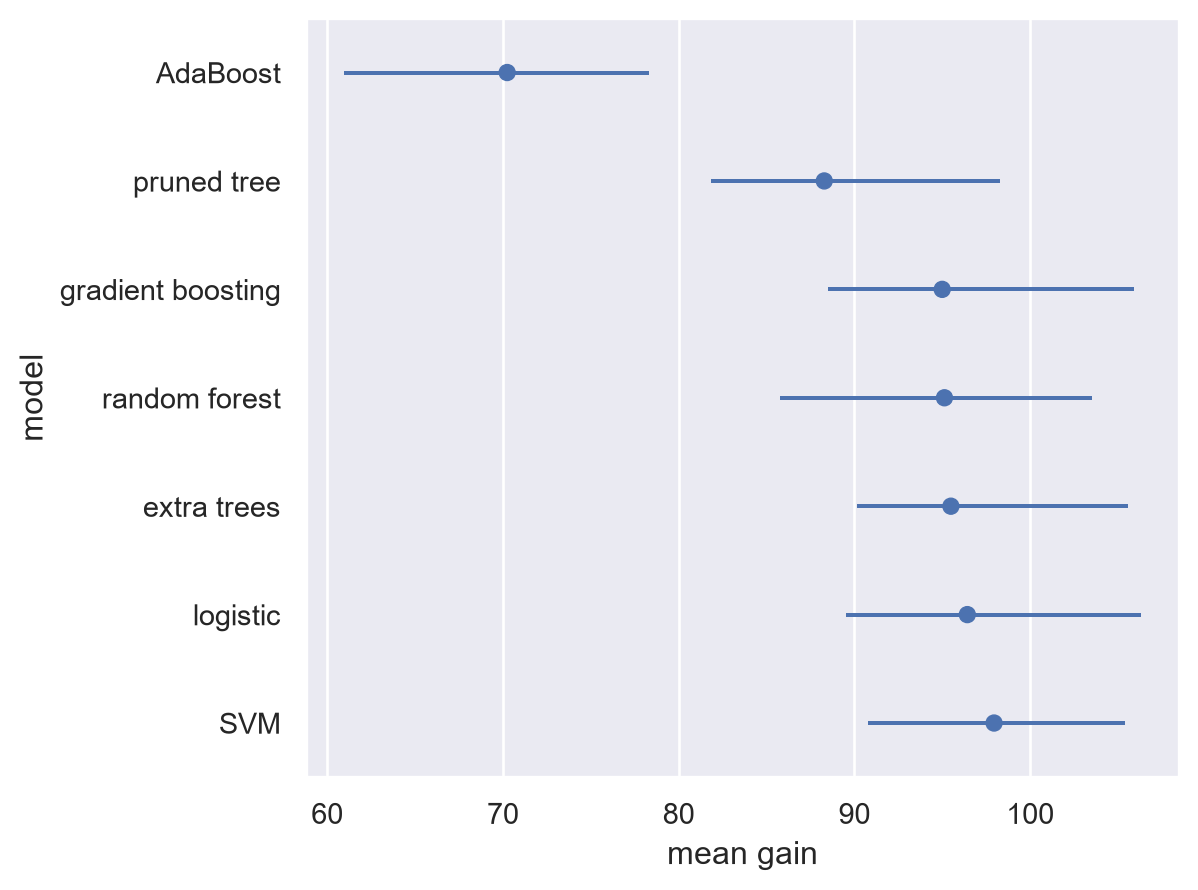

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.calibration import CalibratedClassifierCV
from scipy import stats
svm_parameters = {k.split('__')[1]: v for k, v in svm_grid.best_params_.items()}
models = {'logistic': LogisticRegression(max_iter=1000),
          'pruned tree': DecisionTreeClassifier(ccp_alpha=best_alpha, random_state=0),
          'random forest': RandomForestClassifier(n_estimators=300, max_features=8, random_state=0, n_jobs=2),
          'extra trees': ExtraTreesClassifier(n_estimators=300, max_features=8, min_samples_leaf=3, random_state=0, n_jobs=2),
          'AdaBoost': AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=200, random_state=0),
          'gradient boosting': HistGradientBoostingClassifier(early_stopping=True, random_state=0),
          'SVM': CalibratedClassifierCV(SVC(**svm_parameters), ensemble=False)}  # Platt scaling on cross-validated scores
repeated = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=0)
def fit_procedure(name, X, y):
  if name == 'SVM':
    search = clone(svm_grid).fit(X, y)
    model = CalibratedClassifierCV(search.best_estimator_, ensemble=False)
    return model.fit(X, y)
  if name == 'pruned tree':
    alphas = np.r_[0, np.geomspace(1e-5, 0.1, 24)]
    return GridSearchCV(make_pipeline(DecisionTreeClassifier(random_state=0)),
                        {'classifier__ccp_alpha': alphas}, cv=cv5).fit(X, y)
  return make_pipeline(clone(models[name])).fit(X, y)

def cv_gains(name):
  values = []
  for train, valid in repeated.split(X_train, y_train):
    fitted = fit_procedure(name, X_train[train], y_train[train])
    values.append(cost_scorer_from_proba(fitted, X_train[valid], y_train[valid], LoanAmount=LoanAmount_train[valid]))
  return np.array(values)
gains = {name: cv_gains(name) for name in models}
comparison = pl.DataFrame([{'model': name, 'mean gain': g.mean(), 'lower': g.min(), 'upper': g.max()}
                          for name, g in gains.items()]).sort('mean gain')
print(comparison)
(so.Plot(comparison, y='model', x='mean gain').add(so.Dot()).add(so.Range(), xmin='lower', xmax='upper'))

In [20]:
best = comparison['model'][-1]
d = gains['SVM'] - gains['logistic']
t = d.mean() / np.sqrt((1 / len(d) + 1 / 4) * d.var(ddof=1))
final = fit_procedure(best, X_train, y_train)
{'best': best, 'contrast': 'SVM minus logistic', 'mean difference': d.mean(), 'corrected p-value': 2 * stats.t.sf(abs(t), len(d) - 1),
 'test gain of the best': cost_scorer_from_proba(final, X_test, y_test, LoanAmount=LoanAmount_test)}

{'best': 'SVM',
 'contrast': 'SVM minus logistic',
 'mean difference': np.float64(1.521921490352635),
 'corrected p-value': np.float64(0.124036968655088),
 'test gain of the best': 99.68070718922516}

**Conclusion** With pruning and SVM tuning repeated inside each outer training split, the calibrated SVM has the highest mean gain ($97.94$), followed by logistic regression ($96.42$). Across individual validation folds the respective ranges are $90.91$–$105.29$ and $89.64$–$106.20$. They describe fold variability. The paired SVM-minus-logistic difference is $1.52$ points; an approximate corrected resampled test accounting for training-set overlap gives $p=0.124$. The selected SVM, refitted on the full training set, obtains $99.68$ on the held-out loans. AdaBoost earns $70.24$ despite competitive classification accuracy, illustrating the importance of probabilities for cost-based decisions.

---

## To go further

The following blocks are optional and independent: each of them only uses the objects defined in the core part. Their difficulty is marked by stars: ★ direct extension, ★★ new method, ★★★ longer or research-flavored.

| Block | Lecture | Stars |
|---|---|---|
| Impurity measures | CART | ★ |
| Gradient boosting from scratch | Gradient boosting | ★★ |
| XGBoost, LightGBM and CatBoost | Boosting implementations | ★★ |
| Stacking | Ensembles | ★★ |
| Random Fourier features | Kernels | ★★ |
| The SVM dual problem | Duality, KKT | ★★ |
| Why do trees beat neural networks on tabular data? | Tabular deep learning | ★★ |
| A tabular foundation model: TabICL | Foundation models | ★★ |
| Synthetic tabular data | Tabular data | ★★ |
| Fairness of the selected model | Metrics and ethics (Lecture 4) | ★★ |
| AutoGluon (separate notebook) | AutoML, stacking | ★★ |
| A tiny prior-fitted network | Foundation models | ★★★ |

The packages used in these blocks are installed here:

In [21]:
import sys
!uv pip install --python "{sys.executable}" "xgboost==2.1.4" "lightgbm==4.7.0" "catboost" "tabicl==2.1.1" "torch"

Using Python 3.12.14 environment at: ~\.venvs\apm50441
Checked 5 packages in 36ms


### Impurity measures (★)

A split of a node with proportion $p$ of `Risk` is evaluated by the decrease of an impurity: the misclassification rate $\min(p, 1-p)$, the Gini index $2p(1-p)$ or the entropy $-p\log p - (1-p)\log(1-p)$. The last two are strictly concave, which favors splits creating pure children even when they do not change the majority class.

**Question** Plot the three impurities as functions of $p$ (normalized to have the same maximum). Then compare the CV accuracy of pruned trees grown with the Gini index and with the entropy (`criterion='entropy'`), each with its own $\alpha$ selected by cross validation as in Part 1: the impurity decreases, hence the values of $\alpha$, do not have the same scale for the two criteria. Plot the CV accuracy against the number of leaves for both criteria.

**Answer**

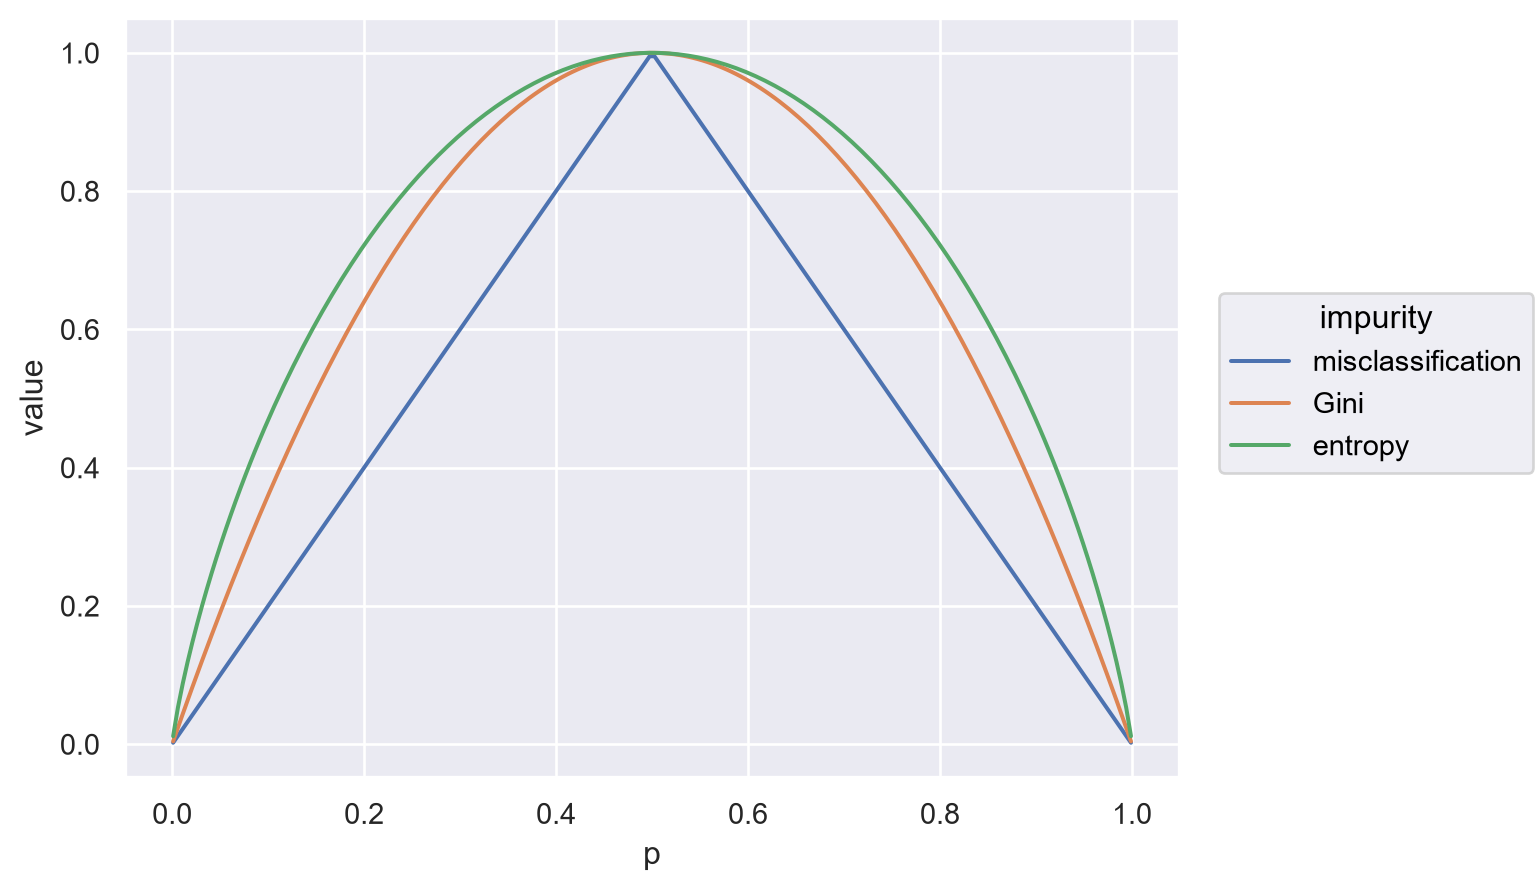

In [22]:
p_grid = np.linspace(0.001, 0.999, 200)
entropy = -(p_grid * np.log(p_grid) + (1 - p_grid) * np.log(1 - p_grid))
impurities = pl.DataFrame({'p': p_grid, 'misclassification': np.minimum(p_grid, 1 - p_grid) / 0.5,
                           'Gini': 2 * p_grid * (1 - p_grid) / 0.5, 'entropy': entropy / np.log(2)})
so.Plot(impurities.unpivot(index='p', variable_name='impurity'), x='p', y='value', color='impurity').add(so.Line())

shape: (2, 5)
┌───────────┬──────────┬────────┬─────────────┬───────────────┐
│ criterion ┆ alpha    ┆ leaves ┆ CV accuracy ┆ test accuracy │
│ ---       ┆ ---      ┆ ---    ┆ ---         ┆ ---           │
│ str       ┆ f64      ┆ i64    ┆ f64         ┆ f64           │
╞═══════════╪══════════╪════════╪═════════════╪═══════════════╡
│ gini      ┆ 0.001063 ┆ 30     ┆ 0.77925     ┆ 0.794         │
│ entropy   ┆ 0.002101 ┆ 28     ┆ 0.774       ┆ 0.783         │
└───────────┴──────────┴────────┴─────────────┴───────────────┘


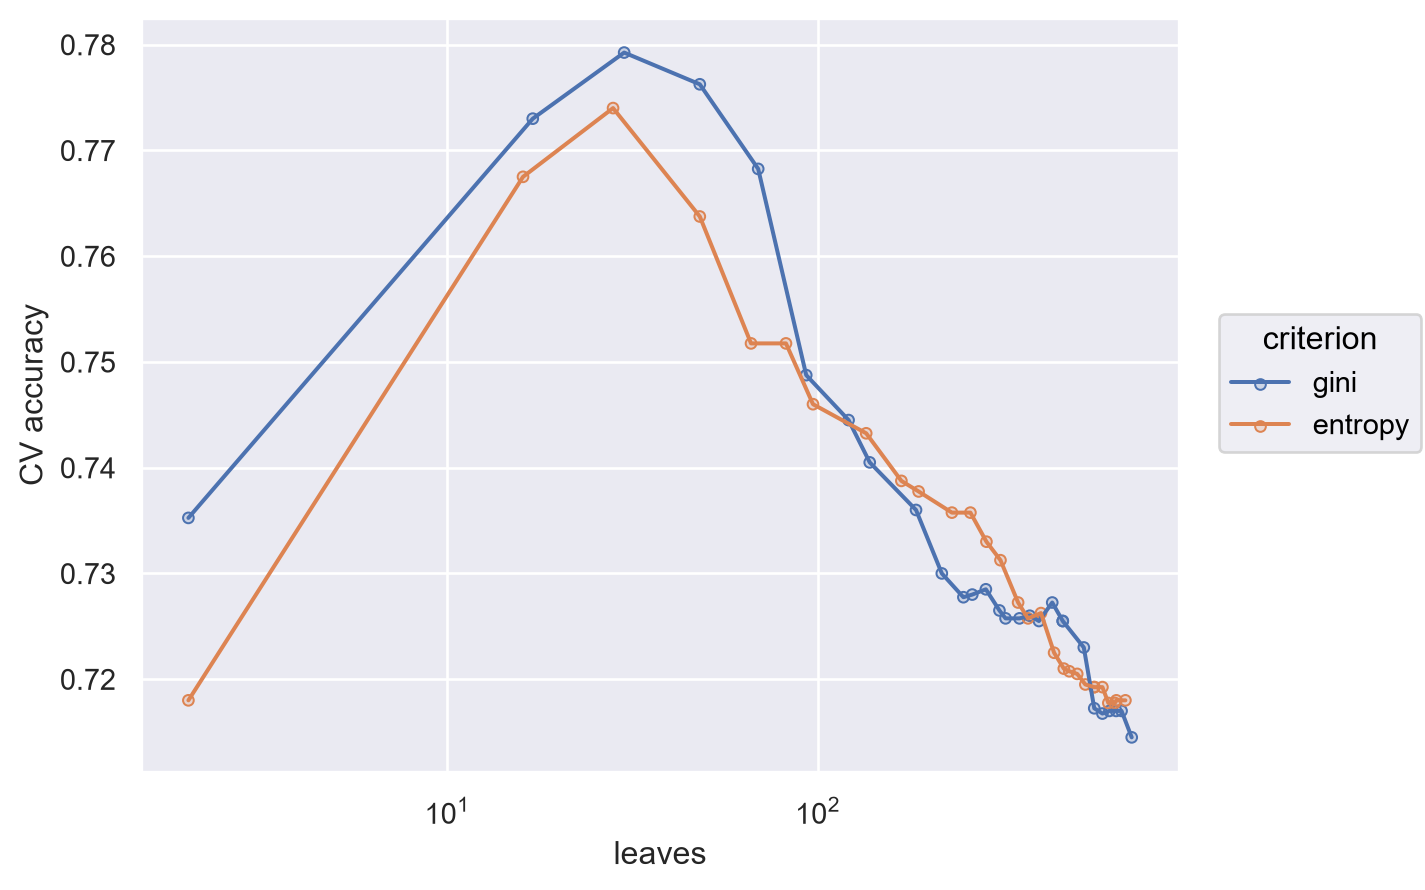

In [23]:
def prune_by_cv(criterion):
  # the pruning path of the full tree grown with this criterion, and the CV accuracy along it (as in Part 1)
  path = DecisionTreeClassifier(criterion=criterion, random_state=0).cost_complexity_pruning_path(Xp_train, y_train)
  rows = []
  for alpha in np.unique(np.quantile(path.ccp_alphas[:-1], np.linspace(0, 1, 30))):
    tree = DecisionTreeClassifier(criterion=criterion, ccp_alpha=alpha, random_state=0)
    rows.append({'criterion': criterion, 'alpha': alpha, 'leaves': clone(tree).fit(Xp_train, y_train).get_n_leaves(),
                 'CV accuracy': cross_val_score(tree, Xp_train, y_train, cv=cv5).mean()})
  return pl.DataFrame(rows)

pruning_criteria = pl.concat([prune_by_cv(criterion) for criterion in ['gini', 'entropy']])
best_trees = []
for criterion in ['gini', 'entropy']:
  best_row = pruning_criteria.filter(pl.col('criterion') == criterion).sort('CV accuracy', 'alpha', descending=[True, False]).row(0, named=True)
  tree = DecisionTreeClassifier(criterion=criterion, ccp_alpha=best_row['alpha'], random_state=0).fit(Xp_train, y_train)
  best_trees.append(best_row | {'test accuracy': tree.score(Xp_test, y_test)})
print(pl.DataFrame(best_trees))
(so.Plot(pruning_criteria, x='leaves', y='CV accuracy', color='criterion').add(so.Line()).add(so.Dots()).scale(x='log'))

**Conclusion** The Gini index and the entropy are strictly concave and very close (after normalization), while the misclassification rate is piecewise linear: a split that creates a purer child without changing the majority class does not decrease the misclassification rate, but decreases the two others, which is why they are used to grow trees. Each criterion needs its own pruning parameter: the selected $\alpha$ is about twice as large for the entropy ($0.0021$) as for the Gini index ($0.0011$), as the two impurities do not have the same scale. With it, the tree grown with the entropy is almost as accurate as the one grown with the Gini index ($0.774$ against $0.779$ in CV, $0.783$ against $0.794$ on the test set), with a similar size ($28$ and $30$ leaves): the difference is within the noise of the cross validation, while it seemed large ($0.736$) with the $\alpha$ of the Gini index. Against the number of leaves, the two CV curves have the same shape and the same optimum (about $30$ leaves): the size of the tree matters much more than the impurity used to grow it.

---

### Gradient boosting from scratch (★★)

For the logistic loss $\ell(y, F) = \log(1 + e^{-yF})$ with $y \in \{-1, 1\}$, the negative gradient at the current score $F(x_i)$ is $r_i = y_i / (1 + e^{y_i F(x_i)})$. Gradient boosting fits a regression tree to the $r_i$ and adds it with a learning rate $\nu$: $F \leftarrow F + \nu\, h$. (For the squared loss, $r_i$ is the residual: boosting is then *residual fitting*.)

**Question** Implement this gradient boosting with regression trees of depth $3$, $\nu = 0.1$ and $200$ trees (starting from the log-odds of the training proportion), and compare its test accuracy along the iterations with `GradientBoostingClassifier` (which also updates the values of the leaves with a Newton step).

**Answer**

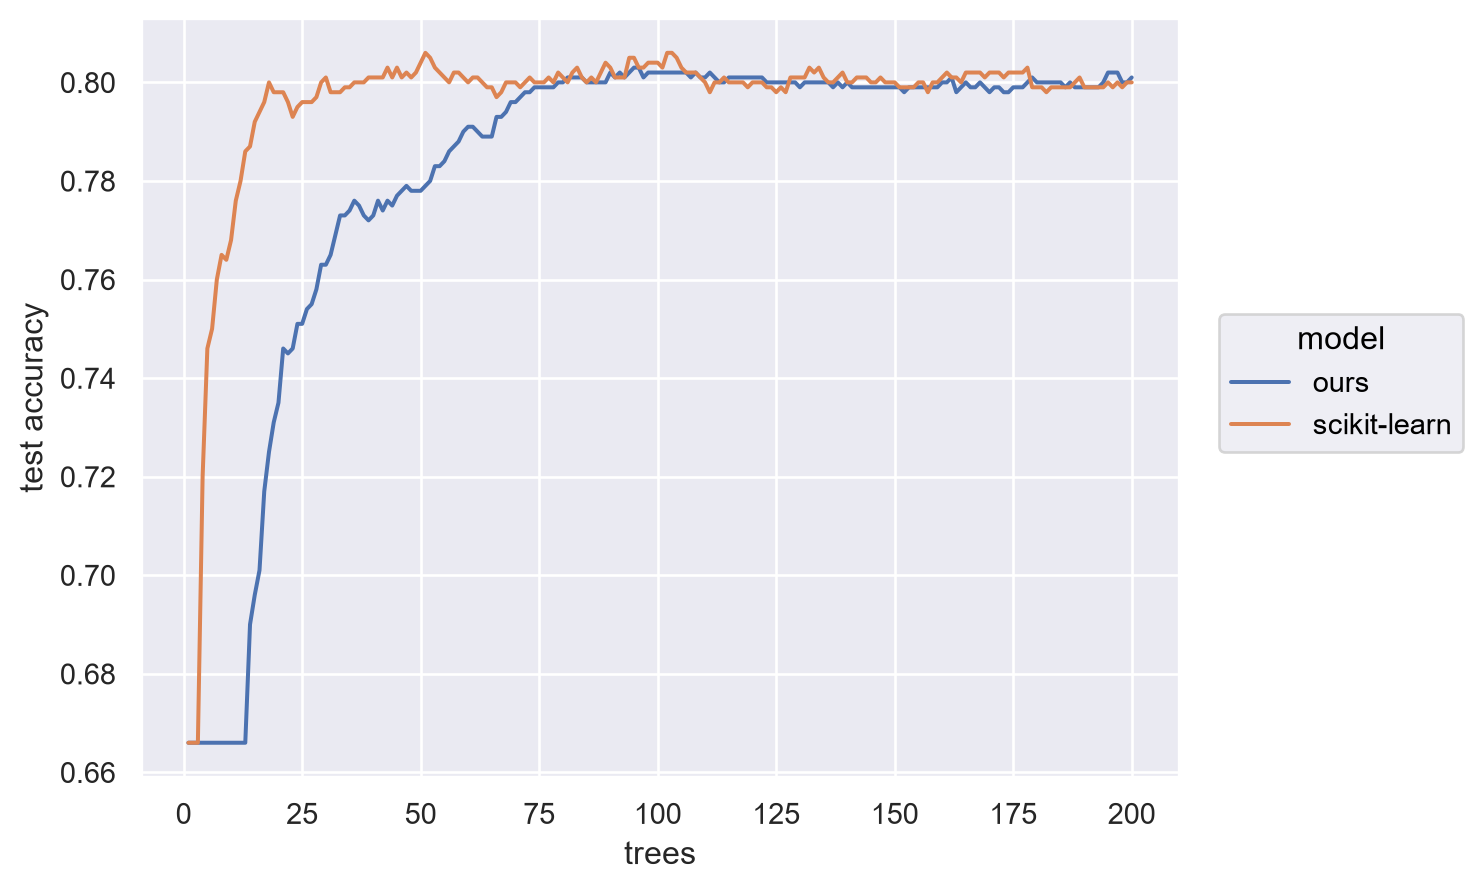

In [24]:
from sklearn.tree import DecisionTreeRegressor
def gradient_boosting(X, y, T, nu=0.1):
  F0 = np.log((y == 1).mean() / (y == -1).mean())
  F, trees = np.full(len(y), F0), []
  for t in range(T):
    residuals = y / (1 + np.exp(y * F))
    tree = DecisionTreeRegressor(max_depth=3, random_state=0).fit(X, residuals)
    F += nu * tree.predict(X)
    trees.append(tree)
  return F0, trees
F0, trees = gradient_boosting(Xp_train, y_pm_train, 200)
scores_test = F0 + 0.1 * np.cumsum([tree.predict(Xp_test) for tree in trees], axis=0)
ours = (np.sign(scores_test) == y_pm_test).mean(axis=1)
gb = GradientBoostingClassifier(learning_rate=0.1, n_estimators=200, max_depth=3, random_state=0).fit(Xp_train, y_pm_train)
theirs = [(prediction == y_pm_test).mean() for prediction in gb.staged_predict(Xp_test)]
so.Plot(pl.DataFrame({'trees': np.arange(1, 201), 'ours': ours, 'scikit-learn': theirs}).unpivot(index='trees', variable_name='model',
        value_name='test accuracy'), x='trees', y='test accuracy', color='model').add(so.Line())

**Conclusion** Both implementations end at the same test accuracy (about $0.80$ after $100$ trees, then a plateau), but ours needs about $70$ trees to get there, against about $20$ for scikit-learn. Both fit a regression tree to the negative gradient; scikit-learn then replaces the value of each leaf by a Newton step on the logistic loss ($\sum r_i / \sum |r_i|(1 - |r_i|)$), which is much larger than the mean residual when the probabilities are not extreme: each tree makes a bigger and better-scaled step. Our version starts flat ($0.67$, the majority class) during $13$ trees, until the score crosses $0$ for some loans.

---

### XGBoost, LightGBM and CatBoost (★★)

The modern boosting libraries differ by their tree growth (*depth-wise* for XGBoost, *leaf-wise* for LightGBM, *symmetric* trees for CatBoost), their handling of categorical features (CatBoost encodes them with ordered target statistics, LightGBM finds optimal partitions of the categories) and many engineering details. XGBoost uses a second-order expansion of the loss: the optimal value of a leaf is $-G/(H + \lambda)$, where $G$ and $H$ are the sums of the gradients and Hessians of its observations.

**Question** Compare the CV gains (Bayes decision, $5$ folds) of XGBoost, LightGBM and CatBoost with their default parameters, the last two with native categorical features (the categorical columns converted to the `category` type), and with the histogram gradient boosting of the core part.

**Answer**

In [25]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.preprocessing import LabelEncoder
import tempfile, contextlib
X_cat = X_train.to_pandas().astype({c: 'category' for c in categorical_features})
y01 = (y_train == 'Risk').to_numpy().astype(int)
def cv_gain(model, X_, y_):
  gains_ = []
  for train, valid in cv5.split(X_, y_):
    model.fit(X_.iloc[train] if hasattr(X_, 'iloc') else X_[train], y_[train])
    proba = model.predict_proba(X_.iloc[valid] if hasattr(X_, 'iloc') else X_[valid])
    gains_.append(-cost_metric(y_train[valid], apm_credit.cost_predict_from_proba(proba, LoanAmount_train[valid]), LoanAmount_train[valid]))
  return np.mean(gains_)
with contextlib.chdir(tempfile.mkdtemp()):  # CatBoost writes its logs in the working directory
  boosting_libraries = {'XGBoost (one-hot)': cv_gain(XGBClassifier(n_estimators=300, learning_rate=0.05, verbosity=0, n_jobs=2), Xp_train, y01),
                        'LightGBM (native categories)': cv_gain(LGBMClassifier(n_estimators=300, learning_rate=0.05, verbose=-1, n_jobs=2), X_cat, y01),
                        'CatBoost (native categories)': cv_gain(CatBoostClassifier(iterations=300, verbose=0, thread_count=2, cat_features=categorical_features), X_cat, y01),
                        'histogram gradient boosting (core)': gains['gradient boosting'].mean()}
boosting_libraries

{'XGBoost (one-hot)': np.float64(94.2441249685314),
 'LightGBM (native categories)': np.float64(94.20541684423947),
 'CatBoost (native categories)': np.float64(98.36969594594595),
 'histogram gradient boosting (core)': np.float64(94.99184554314795)}

**Conclusion** With their default parameters, XGBoost on the one-hot encoded features and LightGBM with native categories reach the same CV gain as the histogram gradient boosting of the core part (about $94$–$95$), while CatBoost is clearly better ($98.4$). Its ordered target statistics for the categorical features and its symmetric trees act as a strong regularization, which suits this small dataset with many categorical variables; its defaults are also more conservative (smaller learning rate, more trees). Defaults matter: the other libraries could be tuned to a similar level, but CatBoost is often the best *out of the box* on categorical data.

---

### Stacking (★★)

Instead of choosing one model, *stacking* learns how to combine them: a final model (here a logistic regression) is trained on the out-of-fold predicted probabilities of the base models.

**Question** Stack the logistic regression, the random forest, the gradient boosting and the SVM with `StackingClassifier`, and compare its CV gain with its members.

**Answer**

In [26]:
from sklearn.ensemble import StackingClassifier
members = {name: clone(models[name]) for name in ['logistic', 'random forest', 'gradient boosting']}
members['SVM'] = SVC(**svm_parameters)  # the stack uses its decision function: no calibration needed
stack = StackingClassifier([(name, make_pipeline(model)) for name, model in members.items()],
                           final_estimator=LogisticRegression(), cv=5)
stack_gain = cross_val_score(stack, X_train, y_train, cv=repeated, scoring=cost_scorer_from_proba, params={'LoanAmount': LoanAmount_train})
{'stacking': stack_gain.mean()} | {name: gains[name].mean() for name in ['logistic', 'random forest', 'gradient boosting', 'SVM']}

{'stacking': np.float64(97.29638039349229),
 'logistic': np.float64(96.42142659276041),
 'random forest': np.float64(95.12058015837694),
 'gradient boosting': np.float64(94.99184554314795),
 'SVM': np.float64(97.94334808311305)}

**Conclusion** The stack obtains a mean gain of $97.3$ in this exploratory calculation. Its base SVM settings were chosen using the full training set. The separately tuned SVM in the core comparison uses nested validation, so subtracting the two reported means would mix evaluation procedures. The stack’s logistic combiner uses out-of-fold scores from the base learners.

---

### Random Fourier features (★★)

A kernel SVM manipulates an $n \times n$ kernel matrix. Random Fourier features (Rahimi and Recht) approximate the RBF kernel with $D$ explicit features $z(x) = \sqrt{2/D}\cos(Wx + b)$, $W \sim \mathcal{N}(0, 2\gamma I)$, $b \sim \mathcal{U}[0, 2\pi]$, so that $\mathbb{E}[z(x)^\top z(x')] = \exp(-\gamma\|x - x'\|^2)$: a linear model on $z(x)$ approximates the kernel method at a cost linear in $n$.

**Question** Compare the test accuracy and the fitting time of the tuned RBF SVM with a logistic regression on $D \in \{50, 200, 1000\}$ random features (`RBFSampler` with the same $\gamma$).

**Answer**

In [27]:
from sklearn.kernel_approximation import RBFSampler
start = time.perf_counter()
svm_best = make_pipeline(SVC(C=svm_grid.best_params_['classifier__C'], gamma=best_gamma)).fit(X_train, y_train)
rows = [{'model': 'RBF SVM', 'test accuracy': svm_best.score(X_test, y_test), 'time (s)': time.perf_counter() - start}]
for D in [50, 200, 1000]:
  start = time.perf_counter()
  rff = Pipeline([('preprocessor', clone(preprocessor)), ('rff', RBFSampler(gamma=best_gamma, n_components=D, random_state=0)),
                  ('classifier', LogisticRegression(C=svm_grid.best_params_['classifier__C'], max_iter=2000))]).fit(X_train, y_train)
  rows.append({'model': f'logistic on {D} random features', 'test accuracy': rff.score(X_test, y_test), 'time (s)': time.perf_counter() - start})
pl.DataFrame(rows)

model,test accuracy,time (s)
str,f64,f64
"""RBF SVM""",0.823,0.553062
"""logistic on 50 random features""",0.787,0.073142
"""logistic on 200 random feature…",0.811,0.110466
"""logistic on 1000 random featur…",0.81,0.238381


**Conclusion** With $50$ random features, the logistic regression is clearly worse than the exact RBF SVM ($0.79$ against $0.82$); with $200$ or $1000$ features it is close ($0.81$), at a fraction of the cost, and its fitting time grows linearly with the number of loans while the one of the kernel SVM grows at least quadratically. On $4000$ loans, the SVM is still fast (about $1$ s); random features become necessary for hundreds of thousands of observations.

---

### The SVM dual problem (★★)

The dual of the soft-margin SVM is $\max_\alpha \sum_i \alpha_i - \frac{1}{2}\sum_{i,j}\alpha_i\alpha_j y_i y_j k(x_i, x_j)$ subject to $0 \leq \alpha_i \leq C$ and $\sum_i \alpha_i y_i = 0$. The KKT conditions show that $\alpha_i = 0$ outside the margin, $0 \leq \alpha_i \leq C$ on the margin (an interior coefficient implies margin equality) and $\alpha_i = C$ inside it: the support vectors are the observations with $\alpha_i > 0$.

**Question** On $300$ training loans, solve the dual with `scipy.optimize.minimize` (method `SLSQP`) for the RBF kernel and the tuned parameters, and compare your $\alpha$ with `SVC`'s `dual_coef_` (which stores $\alpha_i y_i$ for the support vectors).

**Answer**

In [28]:
from scipy.optimize import minimize
from sklearn.metrics.pairwise import rbf_kernel
C_best = svm_grid.best_params_['classifier__C']
Xs, ys = Xp_train[:300], y_pm_train[:300]
K = rbf_kernel(Xs, gamma=best_gamma)
Q = (ys[:, None] * ys[None, :]) * K
result = minimize(lambda a: 0.5 * a @ Q @ a - a.sum(), np.zeros(300), jac=lambda a: Q @ a - 1, method='SLSQP',
                  bounds=[(0, C_best)] * 300, constraints={'type': 'eq', 'fun': lambda a: a @ ys}, options={'maxiter': 500})
alpha_ours = result.x
svc = SVC(C=C_best, gamma=best_gamma).fit(Xs, ys)
alpha_svc = np.zeros(300)
alpha_svc[svc.support_] = np.abs(svc.dual_coef_[0])
{'support vectors (ours, alpha > 1e-4)': int((alpha_ours > 1e-4).sum()), 'support vectors (SVC)': len(svc.support_),
 'at the bound C (ours)': int((alpha_ours > C_best - 1e-4).sum()), 'max |alpha_ours - alpha_svc|': np.abs(alpha_ours - alpha_svc).max()}

{'support vectors (ours, alpha > 1e-4)': 174,
 'support vectors (SVC)': 174,
 'at the bound C (ours)': 116,
 'max |alpha_ours - alpha_svc|': np.float64(0.030003878293806352)}

**Conclusion** Our solution of the dual problem selects the same $174$ support vectors as `SVC` (out of $300$ loans), $116$ of them at the bound $C$ (on or inside the margin, including misclassified points), the others exactly on the margin, as predicted by the KKT conditions. The coefficients agree up to $0.03$, the precision of the general-purpose SLSQP solver; `SVC` uses a dedicated algorithm (SMO) that scales to much larger problems.

---

### Why do trees beat neural networks on tabular data? (★★)

Grinsztajn et al. (2022) identified three inductive biases that favor tree ensembles on tabular data: the target is often irregular (trees can represent sharp steps, neural networks are smooth), many features are uninformative (trees ignore them, neural networks do not), and the features have a meaning on their own (trees are *not* rotation invariant, which helps; neural networks are).

**Question** Train a multilayer perceptron with PyTorch (two hidden layers of $64$ units, Adam, early stopping on a validation split) on the standardized one-hot features, and compare its test accuracy with the gradient boosting. Then apply the same *random rotation* to the features of both: which model suffers?

**Answer**

In [29]:
import torch
def train_mlp(X_fit, y_fit, X_valid, y_valid, epochs=300, seed=0):
  torch.manual_seed(seed)
  net = torch.nn.Sequential(torch.nn.Linear(X_fit.shape[1], 64), torch.nn.ReLU(), torch.nn.Linear(64, 64), torch.nn.ReLU(), torch.nn.Linear(64, 1))
  optimizer = torch.optim.Adam(net.parameters(), lr=1e-3, weight_decay=1e-4)
  xf, yf = torch.tensor(X_fit, dtype=torch.float32), torch.tensor(y_fit, dtype=torch.float32)
  xv, yv = torch.tensor(X_valid, dtype=torch.float32), torch.tensor(y_valid, dtype=torch.float32)
  loss_fn, best, best_state = torch.nn.BCEWithLogitsLoss(), np.inf, None
  for epoch in range(epochs):
    for batch in torch.randperm(len(xf)).split(128):
      optimizer.zero_grad()
      loss_fn(net(xf[batch]).squeeze(1), yf[batch]).backward()
      optimizer.step()
    with torch.no_grad():
      valid_loss = loss_fn(net(xv).squeeze(1), yv).item()
    if valid_loss < best:
      best, best_state = valid_loss, {k: v.clone() for k, v in net.state_dict().items()}
  net.load_state_dict(best_state)
  return net

def mlp_accuracy(net, X_, y_):
  with torch.no_grad():
    return ((net(torch.tensor(X_, dtype=torch.float32)).squeeze(1).numpy() > 0) == y_).mean()

y01_test = (y_test == 'Risk').to_numpy().astype(int)
Xf, Xv, yf_, yv_ = train_test_split(Xp_train, y01, test_size=0.2, random_state=0, stratify=y01)
rotation, _ = np.linalg.qr(np.random.default_rng(0).normal(size=(Xp_train.shape[1], Xp_train.shape[1])))
rows = []
for name, R in {'original features': np.eye(Xp_train.shape[1]), 'rotated features': rotation}.items():
  net = train_mlp(Xf @ R, yf_, Xv @ R, yv_, epochs=100)
  hgb_r = HistGradientBoostingClassifier(early_stopping=True, random_state=0).fit(Xp_train @ R, y01)
  rows.append({'features': name, 'MLP test accuracy': mlp_accuracy(net, Xp_test @ R, y01_test),
               'gradient boosting test accuracy': hgb_r.score(Xp_test @ R, y01_test)})
pl.DataFrame(rows)

features,MLP test accuracy,gradient boosting test accuracy
str,f64,f64
"""original features""",0.815,0.809
"""rotated features""",0.82,0.803


**Conclusion** On the original features, the MLP ($0.815$) and the gradient boosting ($0.809$) are equivalent. After a random rotation of the features, the gradient boosting loses a little ($0.803$) while the MLP is unchanged ($0.82$): a perceptron with a dense first layer is invariant to rotations of its inputs (the rotation can be absorbed in its weights), whereas trees split along the axes and exploit the meaning of each feature. On this dataset, the differences are small: the advantage of trees on tabular data (Grinsztajn et al.) appears mostly with irregular targets and many uninformative features.

---

### A tabular foundation model: TabICL (★★)

Tabular foundation models (TabPFN, TabICL, Lecture 3) are transformers pretrained on millions of synthetic datasets: they predict the test labels *in context*, from the training set, without training nor tuning. TabICL v2 (2026) has open weights; TabPFN (2.5 and later) requires accepting a non-commercial license and a token, which is why we use TabICL here.

**Question** Compute the gain of the Bayes decision on the probabilities of `TabICLClassifier`, and compare it with the CV gains of the core part (and with the test gain of the best model).

**Answer**

In [30]:
from tabicl import TabICLClassifier
from sklearn.preprocessing import OrdinalEncoder
start = time.perf_counter()
tabicl = Pipeline([('encoder', ColumnTransformer([('cat', OrdinalEncoder(), categorical_features)], remainder='passthrough')),
                   ('classifier', TabICLClassifier(random_state=0))]).set_output(transform='pandas').fit(X_train.to_pandas(), y_train.to_pandas())
proba = tabicl.predict_proba(X_test.to_pandas())
{'TabICL test gain': -cost_metric(y_test, apm_credit.cost_predict_from_proba(proba, LoanAmount_test), LoanAmount_test),
 'time (s)': time.perf_counter() - start}

~\.venvs\apm50441\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'TabICL test gain': 97.82347103990219, 'time (s)': 50.82717499999853}

**Conclusion** Without any training nor tuning, TabICL reaches a test gain of $97.8$, in the range of the best tuned models of the core part, in about two minutes on a CPU (the cost is at prediction time, as the whole training set is processed by the transformer for each prediction). Tabular foundation models are a strong default for small and medium datasets.

---

### Synthetic tabular data (★★)

Synthetic data are generated by a model of the joint law of the features (and the label). A simple generator: a Gaussian mixture on the one-hot encoded and standardized features, for each class. A synthetic dataset is useful if a model trained on it performs well on *real* data (*train on synthetic, test on real*).

**Question** Fit, for each class, a Gaussian mixture with $10$ components (diagonal covariances) on the preprocessed training data, sample a synthetic training set of the same size and proportions, train a random forest on it, and compare its test accuracy with the one trained on the real data.

**Answer**

In [31]:
from sklearn.mixture import GaussianMixture
synthetic_X, synthetic_y = [], []
for label in ['No Risk', 'Risk']:
  mask = y_train.to_numpy() == label
  gmm = GaussianMixture(n_components=10, covariance_type='diag', random_state=0).fit(Xp_train[mask])
  samples, _ = gmm.sample(mask.sum())
  synthetic_X.append(samples)
  synthetic_y += [label] * mask.sum()
synthetic_X = np.vstack(synthetic_X)
forest_real = RandomForestClassifier(n_estimators=300, max_features=8, random_state=0, n_jobs=2).fit(Xp_train, y_train)
forest_synthetic = RandomForestClassifier(n_estimators=300, max_features=8, random_state=0, n_jobs=2).fit(synthetic_X, synthetic_y)
{'trained on real data': forest_real.score(Xp_test, y_test), 'trained on synthetic data': forest_synthetic.score(Xp_test, y_test)}

{'trained on real data': 0.806, 'trained on synthetic data': 0.743}

**Conclusion** The random forest trained on the synthetic loans reaches a test accuracy of $0.74$, against $0.81$ when it is trained on the real loans: the Gaussian mixtures reproduce the marginal distributions and part of the dependence of the features within each class, but not all the structure that matters for the prediction (and they ignore that the one-hot columns are binary and exclusive). This *train on synthetic, test on real* score is the standard way to evaluate the utility of synthetic data; their privacy must be evaluated separately (are training loans copied?).

---

### Fairness of the selected model (★★)

The dataset is IBM's *biased* version of the German credit data, and contains sensitive attributes (`Sex`, `ForeignWorker`, `Age`). `apm_credit.fairness_audit` computes, for each attribute, the accuracy, the approval rate and the true and false positive rates by group, as well as the demographic parity difference (difference of approval rates) and the equalized odds difference (Lecture 4, *Metrics and ethics*).

**Question** Audit the Bayes decisions of the best model of the core part on the test set. Then retrain it without `Sex` and `ForeignWorker`: are the differences reduced? Why is *fairness through unawareness* not enough?

**Answer**

In [32]:
decisions = apm_credit.cost_predict(final, X_test, LoanAmount_test)
sensitive = apm_credit.sensitive_features(X_test)
by_group, gaps = apm_credit.fairness_audit(y_test, decisions, sensitive)
print(by_group)
unaware_features = [c for c in X_train.columns if c not in ('Sex', 'ForeignWorker')]
unaware_preprocessor = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
                                           [c for c in categorical_features if c in unaware_features]),
                                          ('num', StandardScaler(), numerical_features)])
unaware = Pipeline([('select', ColumnTransformer([('keep', 'passthrough', unaware_features)], verbose_feature_names_out=False)
                     .set_output(transform='polars')), ('preprocessor', unaware_preprocessor), ('classifier', clone(models[best]))]).fit(X_train, y_train)
_, gaps_unaware = apm_credit.fairness_audit(y_test, apm_credit.cost_predict(unaware, X_test, LoanAmount_test), sensitive)
gaps.join(gaps_unaware, on='attribute', suffix=' (without Sex and ForeignWorker)')

shape: (6, 7)
┌───────────────┬────────────┬───────┬──────────┬───────────────┬──────────┬──────────┐
│ attribute     ┆ group      ┆ count ┆ accuracy ┆ approval rate ┆ TPR      ┆ FPR      │
│ ---           ┆ ---        ┆ ---   ┆ ---      ┆ ---           ┆ ---      ┆ ---      │
│ str           ┆ str        ┆ i64   ┆ f64      ┆ f64           ┆ f64      ┆ f64      │
╞═══════════════╪════════════╪═══════╪══════════╪═══════════════╪══════════╪══════════╡
│ Sex           ┆ female     ┆ 378   ┆ 0.880952 ┆ 0.791005      ┆ 0.97037  ┆ 0.342593 │
│ Sex           ┆ male       ┆ 622   ┆ 0.794212 ┆ 0.813505      ┆ 0.977273 ┆ 0.526549 │
│ ForeignWorker ┆ no         ┆ 23    ┆ 0.695652 ┆ 0.652174      ┆ 1.0      ┆ 0.466667 │
│ ForeignWorker ┆ yes        ┆ 977   ┆ 0.830092 ┆ 0.808598      ┆ 0.974164 ┆ 0.467085 │
│ AgeGroup      ┆ 25 or less ┆ 195   ┆ 0.948718 ┆ 1.0           ┆ 1.0      ┆ 1.0      │
│ AgeGroup      ┆ over 25    ┆ 805   ┆ 0.797516 ┆ 0.757764      ┆ 0.964657 ┆ 0.450617 │
└───────────────┴─

attribute,demographic parity difference,equalized odds difference,demographic parity difference (without Sex and ForeignWorker),equalized odds difference (without Sex and ForeignWorker)
str,f64,f64,f64,f64
"""Sex""",0.0225,0.183956,0.107904,0.167486
"""ForeignWorker""",0.156424,0.025836,0.053625,0.099269
"""AgeGroup""",0.242236,0.549383,0.204969,0.441358


**Conclusion** The audit shows large differences between groups. Applicants aged $25$ or less are *all* approved (approval rate $1$, false positive rate $1$: none of their risky loans is refused), against $76\%$ for the older ones, hence large demographic parity ($0.24$) and equalized odds ($0.55$) differences. Women are approved about as often as men (difference $0.02$), but with a much lower false positive rate ($0.34$ against $0.53$). Retraining without `Sex` and `ForeignWorker` does not remove the differences: for the sex, the demographic parity difference even increases ($0.11$), and the equalized odds difference for the foreign workers increases too. The sensitive attributes are correlated with other features (proxies), and removing them changes the model in unpredictable ways: *fairness through unawareness* is not a guarantee, fairness must be measured, and corrected explicitly if needed (e.g. with `fairlearn`'s `ThresholdOptimizer`).

---

### AutoGluon (★★, separate notebook)

AutoGluon trains many models (boosting libraries, random forests, neural networks, foundation models) and *stacks* them in several layers, with a time budget. As it pins many packages, it has its own short notebook, `APM_50441_EP_Lab_3_AutoGluon.ipynb`: open it on Colab (*Open in Colab* link), or run it on your own computer in a separate environment (see its *Working environment*). It covers AutoGluon in three minutes, what is inside (bagging and stacking), and the tabular foundation models TabICLv2 and TabDPT used through AutoGluon, compared with the models of this lab.

---

### A tiny prior-fitted network (★★★)

A *prior-fitted network* (PFN, the idea behind TabPFN) is a transformer trained on many small *synthetic* datasets drawn from a prior: it receives a training set and test inputs, and learns to output the posterior predictive distribution of the test labels. Here, the prior generates 1D regression datasets $y = a\sin(\omega x + \phi) + \varepsilon$ with random $a$, $\omega$, $\phi$; after training, the network predicts *in context* on a new dataset, without any gradient step.

**Question** Train a small transformer (PyTorch, $2$ layers, the training points as tokens $(x_i, y_i)$, the test points as tokens $(x_j, 0)$ attending only to the training tokens) on $3000$ batches of $32$ synthetic datasets of $20$ training and $20$ test points. Compare its predictions on a new dataset with a kernel ridge regression.

**Answer**

In [33]:
import torch
torch.manual_seed(0)
def prior_batch(batch=32, n_train=20, n_test=20):
  a = torch.rand(batch, 1) * 2 + 0.5; omega = torch.rand(batch, 1) * 4 + 1; phi = torch.rand(batch, 1) * 6.28
  x = torch.rand(batch, n_train + n_test) * 2 - 1
  y = a * torch.sin(omega * x + phi) + 0.1 * torch.randn_like(x)
  return x, y
class TinyPFN(torch.nn.Module):
  def __init__(self, d=64, layers=2):
    super().__init__()
    self.embed_train, self.embed_test = torch.nn.Linear(2, d), torch.nn.Linear(1, d)
    self.encoder = torch.nn.TransformerEncoder(torch.nn.TransformerEncoderLayer(d, 4, 128, batch_first=True, dropout=0.0), layers)
    self.head = torch.nn.Linear(d, 1)
  def forward(self, x_train, y_train, x_test):
    tokens = torch.cat([self.embed_train(torch.stack([x_train, y_train], -1)), self.embed_test(x_test[..., None])], 1)
    n_train, n = x_train.shape[1], tokens.shape[1]
    mask = torch.ones(n, n, dtype=torch.bool)
    mask[:, :n_train] = False  # every token attends to the training tokens only
    return self.head(self.encoder(tokens, mask=mask)[:, n_train:]).squeeze(-1)
pfn = TinyPFN()
optimizer = torch.optim.Adam(pfn.parameters(), lr=1e-3)
losses = []
for step in range(3000):
  x, yb = prior_batch()
  loss = torch.mean((pfn(x[:, :20], yb[:, :20], x[:, 20:]) - yb[:, 20:]) ** 2)
  optimizer.zero_grad(); loss.backward(); optimizer.step()
  losses.append(loss.item())
print('final training loss (mean of the last 100 steps):', np.mean(losses[-100:]))

final training loss (mean of the last 100 steps): 0.03158211724832654


In [34]:
from sklearn.kernel_ridge import KernelRidge
torch.manual_seed(1)
x, yb = prior_batch(batch=200)
with torch.no_grad():
  pred_pfn = pfn(x[:, :20], yb[:, :20], x[:, 20:]).numpy()
pred_krr = np.array([KernelRidge(alpha=0.01, kernel='rbf', gamma=5).fit(x[i, :20, None].numpy(), yb[i, :20].numpy())
                     .predict(x[i, 20:, None].numpy()) for i in range(200)])
{'PFN test MSE (200 new datasets)': np.mean((pred_pfn - yb[:, 20:].numpy()) ** 2),
 'kernel ridge test MSE': np.mean((pred_krr - yb[:, 20:].numpy()) ** 2)}

{'PFN test MSE (200 new datasets)': np.float32(0.03367264),
 'kernel ridge test MSE': np.float32(0.020680169)}

**Conclusion** After $3000$ batches of synthetic tasks, the small transformer predicts the test points of new datasets *in context*, without any gradient step on them, with a mean squared error of $0.034$, of the same order as a kernel ridge regression fitted on each dataset with well-chosen hyperparameters ($0.021$). It has learned an approximation of the posterior predictive of the prior used to generate the tasks; TabPFN and TabICL apply the same idea at a much larger scale, with priors designed to cover real tabular data.

---

## About this lab

**Use of AI.** Artificial intelligence tools have been used to revise the content of this lab. The main contributor takes full responsibility for this content.

**License.** The texts of this lab are under the [Creative Commons Attribution-ShareAlike 4.0](https://creativecommons.org/licenses/by-sa/4.0/) license (CC BY-SA 4.0), and its code under the [MIT](https://opensource.org/license/mit) license; the datasets keep their own licenses. Main contributor: E. Le Pennec. Contributors: S. Boucheron, A. Dieuleveut, A.K. Fermin, S. Gadat, S. Gaiffas, B. Goujaud, A. Guilloux, Ch. Keribin, Th. Klein, E. Matzner, J. Read, M. Sangnier, E. Scornet.